# 1. A lunar lander with a fuel tank: imposing a budget on a controller in use

A lander controller is in use. It was trained on Gymnasium's LunarLanderContinuous, which rewards a soft landing
on the pad, punishes a crash, and charges the fuel the engines burn. Now the lander gets a tank of 24 units, and a
lander that empties it before touching down has failed. The tank is smaller than the controller needs: in a typical
landing it burns more than 24 units.

This is a common situation: a policy works, and a new limit arrives (a smaller tank, a battery, a quota). This
notebook shows how to impose the limit with barrier policy gradients:

1. evaluate the controller in use under the new limit;
2. state the requirement and check whether another method is the better choice;
3. continue training the controller with the tank, at several prices;
4. use the controller in use as the prior: a parameter anchor and an action anchor;
5. validate the policy to deploy and report.

The trained policies come from the campaign in `campaigns/` (PPO, three seeds per configuration); this notebook
loads them, so it runs in minutes. It needs Gymnasium with Box2D.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve() / "campaigns"))
from records import Campaign
from bpg import Requirement, Stage, evaluate, interpret, plan
from bpg.problems.lander import Tank, make_lander_env, fuel_use

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
camp = Campaign("lander")
tank = Tank()
spec = tank.spec()

## 1. The controller in use under the new tank

Each frame burns 0.30 per unit of main-engine power and 0.03 per unit of side-engine power. The wrapper adds the
remaining fuel, as a fraction of the tank, to the observation, ends the episode when the tank is empty, and charges
the price there. The controller in use was trained with a fuel gauge that never ran dry, so the gauge is a familiar
input; it simply never had a reason to save fuel. How much fuel does it burn, and how often would it run dry?

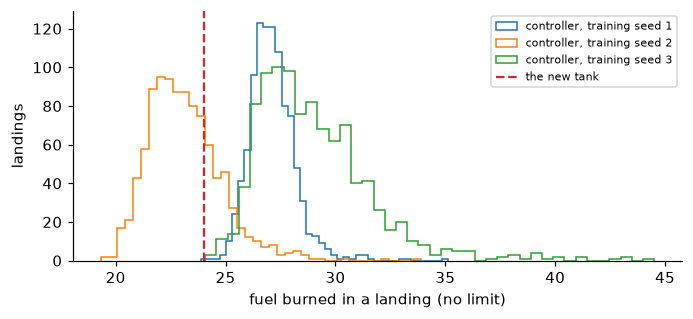

controller seed 1 under the tank: ran dry 100.0%, landed   0.0%, crashed  0.0%
controller seed 2 under the tank: ran dry  25.4%, landed  72.2%, crashed  2.4%
controller seed 3 under the tank: ran dry  99.9%, landed   0.1%, crashed  0.0%


In [2]:
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for s in camp.seeds("controller"):
    fuel = np.array(camp.record("controller", s)["evaluation"]["fuel"])
    ax.hist(fuel, bins=40, histtype="step", label=f"controller, training seed {s}")
ax.axvline(tank.capacity, color="C3", ls="--", label="the new tank")
ax.set_xlabel("fuel burned in a landing (no limit)"); ax.set_ylabel("landings"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

for s in camp.seeds("controller"):
    e = camp.record("controller", s)["extra_evaluations"][0]["episodes"]
    print(f"controller seed {s} under the tank: ran dry {np.mean(e['failed']):6.1%}, landed {np.mean(e['landed']):6.1%}, "
          f"crashed {np.mean(e['crashed']):5.1%}")

Retraining from scratch with the tank is no way out: random exploration empties the tank long before it lands.

In [3]:
fuel_per_frame = np.mean([fuel_use(a) for a in np.random.default_rng(0).uniform(-1, 1, (100_000, 2))])
print(f"random actions burn {fuel_per_frame:.3f} per frame: the tank is empty after about {tank.capacity / fuel_per_frame:.0f} frames")

random actions burn 0.123 per frame: the tank is empty after about 195 frames


So the budget is imposed by continuing to train the controller in use, with the tank.

## 2. The requirement

The lander should run dry in at most 5% of landings, shown at 95% confidence; an episode lasts at most 1000 frames.
The task's crash penalty (-100) lies below any sensible price, so the stage prices only the failure
(`clip_utility=False`) and leaves the task's own rewards as they are.

In [4]:
req = Requirement(T=spec.horizon - 1, alpha=0.05, zeta=0.05, family=10)
p = plan(spec, req, stage=Stage(m=0.5, clip_utility=False), failure_permissible_at_deployment=True,
         violations_during_training_matter=False, loss_grows_with_excess_consumption=False, model_known_and_small=False,
         episode_earnings=240.0)
print(p.explain())

Requirement: p_T <= 0.05 at T = 999 (1000 actions), validation error 0.05 shared by 10 statements; kind = finite.
When another method is the better choice [paper, 'Which formulation to prefer']:
  [does not apply] no failure is permissible and a controlled-invariant set is known: an almost-sure method (an infinite failure penalty, a control-barrier safety layer, or a method that learns which actions keep probability-one budget constraints). Reason: a finite price prices failure risk and does not prohibit failure; a class of full-support policies can have a positive risk floor.
  [not stated] a prescribed level is attainable with slack and the multiplier's step can be tuned: an adaptive multiplier (a Lagrangian chance-constrained policy gradient). Reason: a fixed price leaves the attained risk to the optimizer, and unused risk costs utility; with too large a step the multiplier increases without bound when the initial policy fails often, as in the fuel-tank study.
  [does not apply] vio

## 3. Continuing training with the tank, at several prices

Each run continues the controller of its seed for 3 million frames with the tank, at a price of 0 (the tank alone),
0.25, 0.5, 1 or 2 per frame from the failure to the end of the episode.

configuration    seeds        failure (min-max)          utility (min-max)
tank-unpriced        3     3.300% (1.30%-6.00%)        241.5 (235.3-247.3)
price-0.25           3     4.667% (2.90%-7.00%)        236.9 (231.6-243.8)
price-0.5            3     6.833% (5.50%-8.10%)        223.4 (187.3-246.9)
price-1              3     5.833% (2.70%-9.30%)          212 (195.9-235.7)
price-2              3     3.933% (2.10%-7.20%)        193.4 (169.1-234.1)


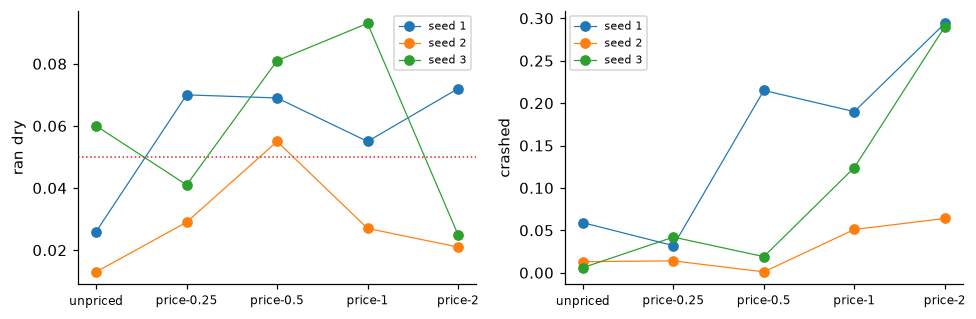

In [5]:
prices = ["tank-unpriced", "price-0.25", "price-0.5", "price-1", "price-2"]
print(Campaign.show(camp.table(prices, extras=("landed", "crashed"))))

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
x = np.arange(len(prices))
for k, key in enumerate(["failed", "crashed"]):
    for s in (1, 2, 3):
        vals = [np.mean(camp.record(c, s)["evaluation"][key]) if s in camp.seeds(c) else np.nan for c in prices]
        ax[k].plot(x, vals, "o-", lw=0.8, label=f"seed {s}")
    ax[k].set_xticks(x, [c.replace("tank-", "") for c in prices], fontsize=8)
    ax[k].set_ylabel({"failed": "ran dry", "crashed": "crashed"}[key]); ax[k].legend(fontsize=7)
ax[0].axhline(req.alpha, color="C3", ls=":", lw=1)
plt.tight_layout(); plt.show()

Continuing to train with the tank teaches the lander to save fuel even without a price: running dry ends the
episode before the landing bonus, so the task's own reward already punishes it. The price adds little to that. Higher
prices barely change how often the lander runs dry and make it crash more often, in some seeds in a quarter of the
landings or more. Once running dry costs more than a crash, the learner sometimes chooses the crash.

This is the general caution about a price: it applies to running out only. Compare it with the cost of the other ways
an episode can end badly in your task. Here continuing with the tank alone met the tolerance in two of three seeds,
and no price did better: the task's own reward already priced running dry high enough.

## 4. The controller in use as the prior

The controller in use is the policy one would accept if training gained nothing, which makes it the natural prior.
Two regularizers use it differently, both at the price 0.5:

* a **parameter anchor** pulls the network's weights back toward the controller's (strengths from 0.01 to 10);
* an **action anchor** charges, at every frame, how far the policy's action distribution departs from the
  controller's (weight 0.05).

In [6]:
regs = ["price-0.5", "anchor-0.01", "anchor-0.1", "anchor-1", "anchor-10", "action-anchor"]
print(Campaign.show(camp.table(regs, extras=("landed", "crashed"))))
for cfg in ["anchor-0.01", "anchor-0.1", "anchor-1", "anchor-10"]:
    print(f"{cfg}: weight distance from the controller at the end {np.round([r['anchor_distance'] for r in camp.records(cfg)], 3)}")
print("action-anchor: mean log ratio to the controller per frame", np.round([r["action_log_ratio"] for r in camp.records("action-anchor")], 3))

configuration    seeds        failure (min-max)          utility (min-max)
price-0.5            3     6.833% (5.50%-8.10%)        223.4 (187.3-246.9)
anchor-0.01          3  68.633% (19.60%-97.20%)          153 (117.3-214.9)
anchor-0.1           3  71.500% (19.20%-98.30%)        148.6 (114.7-215.7)
anchor-1             3   69.300% (8.80%-99.90%)        138.6 (108.5-194.3)
anchor-10            3  89.200% (72.70%-99.80%)          127 (108.3-152.8)
action-anchor        3     4.867% (1.40%-8.70%)        226.3 (212.5-245.2)
anchor-0.01: weight distance from the controller at the end [0.037 0.01  0.033]
anchor-0.1: weight distance from the controller at the end [0.102 0.113 0.082]
anchor-1: weight distance from the controller at the end [0.201 0.265 0.196]
anchor-10: weight distance from the controller at the end [0.267 0.288 0.268]
action-anchor: mean log ratio to the controller per frame [2.361 0.404 1.668]


The parameter anchor keeps the controller's flaw. The controller runs dry under the new tank, and anchored to its
weights the lander keeps running dry, at every strength tried, down to 0.01. The learner inherits the risk of the prior
policy, and here the prior policy is one the new requirement rejects. Under Adam, which rescales every gradient, even a
weak pull on the weights outweighs the policy gradient.

The action anchor works differently. It charges, at every frame, how far the policy's action distribution departs from
the controller's, so it holds the behavior near the controller and gives way where the tank demands a change. With it
the lander learned to save fuel as well as without it. Its effect on crashes was mixed: fewer in the seed where the
price alone crashed most, slightly more in the other two, and about the same on average.

When the policy in use violates the new limit: start from it, and if you regularize toward it, regularize its
behavior, not its weights.

## 5. Validate the policy to deploy, and report

Ten candidates were inspected, so the validation error is shared among ten. We take the candidate with the highest
landing rate among those that met the tolerance on their first evaluation, and validate it on 2,000 fresh landings,
as a stochastic policy and as its mean action, which are different candidates.

In [7]:
cands = [(c, s) for c in prices + regs[1:] for s in camp.seeds(c)]
ok = [cs for cs in cands if np.mean(camp.record(*cs)["evaluation"]["failed"]) < req.alpha]
best = max(ok, key=lambda cs: np.mean(camp.record(*cs)["evaluation"]["landed"]))
print("candidate:", best, camp.record(*best)["note"])
stage = camp.stage(*best)
for det in (False, True):
    e = evaluate(lambda: make_lander_env(stage, tank), camp.policy(*best, deterministic=det), 2000, spec=spec, stage=stage,
                 T=req.T, seed=777)
    name = f"the {'mean action of the' if det else 'stochastic'} policy {best[0]}, seed {best[1]}"
    print()
    print(interpret(spec, req, stage, e, candidate_name=name).summary(resource="fuel", period="frames"))

candidate: ('tank-unpriced', 2) the tank imposed, no price


The stochastic policy tank-unpriced, seed 2 was run on 2000 fresh episodes. It ran out of fuel within 1000 frames in 25 of them (1.25%).
With confidence 0.95, its probability of running out within 1000 frames is at most 2.042% (the error 0.05 is shared among 10 candidates).
Requirement (at most 5.00%): met.
Utility per episode: 246.8 (standard error 0.73).
Episodes that came within 5% of running out, or ran out: 5.8%.

What this test does not show:
  - that the policy is the best possible at this risk: how far training fell short of the optimum is not measured;
  - its risk over more than 1000 frames, or that of other policies (its mean action, a retrained network);
  - its behavior outside the simulator.
Every bound with its assumptions: report.text().



The mean action of the policy tank-unpriced, seed 2 was run on 2000 fresh episodes. It ran out of fuel within 1000 frames in 24 of them (1.20%).
With confidence 0.95, its probability of running out within 1000 frames is at most 1.979% (the error 0.05 is shared among 10 candidates).
Requirement (at most 5.00%): met.
Utility per episode: 245.1 (standard error 0.69).
Episodes that came within 5% of running out, or ran out: 7.7%.

What this test does not show:
  - that the policy is the best possible at this risk: how far training fell short of the optimum is not measured;
  - its risk over more than 1000 frames, or that of other policies (its mean action, a retrained network);
  - its behavior outside the simulator.
Every bound with its assumptions: report.text().


The candidate that learned the tank without a price passes, as a stochastic policy and as its mean action. On this
task, imposing the tank and continuing to train did the work and the price had nothing to add; the validation is
what shows that the policy meets the requirement.

## Train it yourself

```bash
python campaigns/run.py lander controller --seed 4        # the controller in use, about 10 minutes
python campaigns/run.py lander price-0.5 --seed 4         # continue it with the tank, about 7 minutes
```

`bpg/problems/lander.py` maps the task to a budget in a few lines and is a template for your own problem.